# Extracting topographic lineaments from SRTM hillshades

This notebook downloads and reprojects elevation data, generates a hillshade for each configured illumination, detects segments independently for each illumination, and exports geometries, tables, maps, and rose diagrams. The worked example covers part of **Serra da Canastra, Minas Gerais, Brazil**, near the source of the São Francisco River. [Study area described by ICMBio](https://www.gov.br/icmbio/pt-br/assuntos/unidade-de-conservacao/unidades-de-biomas/cerrado/lista-de-ucs/parna-da-serra-da-canastra/historia-do-parque-nacional-da-serra-da-canastra)

## 1. Set up the environment

Install GMT so that its native library is available to PyGMT, then select a Python kernel in Jupyter. The versions below reproduce the reference environment. Network access is required if GMT has yet to cache the SRTM data. [Installing PyGMT and GMT](https://www.pygmt.org/v0.19.0/install.html)

The reference environment uses **Python 3.14.5 and GMT 6.6.0**. Run the following command in the terminal for the environment that provides the kernel.

```bash
python -m pip install numpy==2.5.2 scipy==1.18.1 scikit-image==0.26.0 rasterio==1.5.1 geopandas==1.1.4 pyogrio==0.13.0 pyproj==3.7.2 shapely==2.1.2 matplotlib==3.11.1 pandas==3.0.5 pygmt==0.19.0 pillow==12.3.0 ipykernel==7.4.0
```

In [1]:
from colorsys import hsv_to_rgb
from dataclasses import dataclass
from datetime import date
from hashlib import file_digest
from importlib.metadata import version
from io import BytesIO
from itertools import count
import math
from pathlib import Path
import platform
from tempfile import TemporaryDirectory
from xml.etree import ElementTree as ET

import geopandas as gpd
from IPython.display import Image as NotebookImage, display
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.ticker import MaxNLocator, PercentFormatter, ScalarFormatter
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFont
from pyproj import Geod, Transformer
import pygmt
import rasterio
from rasterio.io import MemoryFile
from rasterio.warp import calculate_default_transform, reproject, Resampling, transform_bounds
from scipy import ndimage as ndi
from scipy.ndimage import binary_erosion, gaussian_filter
from shapely.geometry import LineString
from skimage.filters import sato
from skimage.morphology import skeletonize
from skimage.transform import probabilistic_hough_line

print("Python", platform.python_version())
print("PyGMT", version("pygmt"), "· GDAL", rasterio.__gdal_version__)

Python 3.14.5
PyGMT 0.19.0 · GDAL 3.12.4


## 2. Configure the study area and illuminations

Enter the area name and two opposite corners of the study area. Coordinates use **WGS84 (EPSG:4326)** in decimal degrees, in **`(latitude, longitude)`** order, as in Google Maps.

In Google Maps, right-click the first corner and click its coordinates to copy them. Paste the pair inside the parentheses for `CORNER_1` and repeat for `CORNER_2`. Use a decimal point. The example is prefilled with Serra da Canastra. [Copy coordinates from Google Maps](https://support.google.com/maps/answer/18539?co=GENIE.Platform%3DDesktop&hl=en)

Add or remove pairs in `ILLUMINATIONS` to set the number of hillshades to generate and analyse. Each pair specifies `(azimuth, solar elevation)` in degrees. Azimuth is measured clockwise from UTM grid north and solar elevation is measured above the horizon. Supply at least one pair and use distinct pairs. The notebook processes each illumination independently in the order listed.

`MIN_LENGTH_M` is in metres. Results are written to `./linextraction_resultados/<AREA_NAME>/`. A new run uses a suffix such as `_02` if the directory already exists. Set the kernel's working directory to the directory containing the notebook.
**Elevation source:** set `ELEVATION_MODEL = "copernicus"` (no key), `"alos"` (AW3D30), `"anadem"` or keep `"srtm"` (default).

**OpenTopography key.** For `alos` or `anadem`, run the elevation acquisition cell. Paste the key into the hidden **OpenTopography API key** field and press Enter. The notebook uses `OPENTOPOGRAPHY_API_KEY` directly if it is already set in the environment.

Alternative inputs are saved in `dem/`; SRTM keeps `srtm/srtm.tif`. All later processing is unchanged.

Set `IMAGE_FORMAT` to choose the figure format. The default is `"svg"`. Select `"png"` to export raster images.


In [2]:
# Paste the corners in (latitude, longitude) order, as in Google Maps.
AREA_NAME = "Serra da Canastra"
CORNER_1 = (-20.36, -46.72)
CORNER_2 = (-20.11, -46.31)

# srtm (default), copernicus (COP30), alos (AW3D30), anadem.
ELEVATION_MODEL = "srtm"
IMAGE_FORMAT = "svg"

# One hillshade per (azimuth, solar elevation) pair, in degrees.
ILLUMINATIONS = [
    (45, 45),
    (135, 45),
    (225, 45),
    (315, 45),
]

MIN_LENGTH_M = 600.0
SENSITIVITY = "very-high"
OUTPUT_DIR = Path("linextraction_resultados") / AREA_NAME

latitude_1, longitude_1 = CORNER_1
latitude_2, longitude_2 = CORNER_2
west, east = sorted((longitude_1, longitude_2))
south, north = sorted((latitude_1, latitude_2))
if not (-180 <= west < east <= 180 and -90 <= south < north <= 90):
    raise ValueError("Enter two valid opposite corners in (latitude, longitude) order.")
if IMAGE_FORMAT not in ("svg", "png"):
    raise ValueError("Choose svg or png for IMAGE_FORMAT.")
if ELEVATION_MODEL not in ("srtm", "copernicus", "alos", "anadem"):
    raise ValueError("Choose srtm, copernicus, alos, or anadem.")
if not ILLUMINATIONS:
    raise ValueError("Enter at least one illumination.")
if not all(0 <= az < 360 and 0 <= alt <= 90 for az, alt in ILLUMINATIONS):
    raise ValueError("Use azimuths from 0° to less than 360° and solar elevations from 0° to 90°.")
if len(set(ILLUMINATIONS)) != len(ILLUMINATIONS):
    raise ValueError("Enter distinct azimuth and solar elevation pairs.")
if not math.isfinite(MIN_LENGTH_M) or MIN_LENGTH_M <= 0:
    raise ValueError("Enter a positive minimum length in metres.")

if (
    not AREA_NAME.strip() or AREA_NAME in (".", "..") or AREA_NAME.endswith((".", " "))
    or any(character in AREA_NAME for character in '/\\:*?"<>|')
):
    raise ValueError("Use an area name that is valid as a single directory name.")

REGION = west, east, south, north
print(f"{AREA_NAME} · WGS84 bounds (W, E, S, N) {REGION}")
print(f"Configured illuminations · {len(ILLUMINATIONS)}")

Serra da Canastra · WGS84 bounds (W, E, S, N) (-46.72, -46.31, -20.36, -20.11)
Configured illuminations · 4


## 3. Download elevation data and reproject to UTM

The study area uses the one-arc-second SRTM data distributed by GMT. The notebook exports the original GeoTIFF in WGS84 to `srtm/`. It reprojects an intermediate copy with bilinear resampling to the UTM zone at the centre of the study area so that distances can be measured in metres. [SRTM data in GMT](https://www.generic-mapping-tools.org/remote-datasets/srtm-relief.html) · [NASA SRTMGL1 V003](https://doi.org/10.5067/MEaSUREs/SRTM/SRTMGL1.003)

In [3]:
def download_srtm(region, destination):
    import pygmt

    with TemporaryDirectory() as temp:
        grid = Path(temp) / "srtm.nc"
        pygmt.grdcut(grid="@srtm_relief_01s", region=region, outgrid=grid)
        with rasterio.open(grid) as src:
            elevation = src.read(1, masked=True).astype(np.float32)
            profile = dict(
                driver="GTiff", height=src.height, width=src.width, count=1,
                dtype="float32", crs="EPSG:4326", transform=src.transform,
                nodata=np.nan, compress="lzw",
            )
        if min(elevation.shape) < 2 or elevation.count() == 0:
            raise ValueError("The SRTM subset must have at least two rows and two columns of elevation data.")
        with rasterio.open(destination, "w", **profile) as dst:
            dst.write(elevation.filled(np.nan), 1)


SOURCE_CRS = "EPSG:4326"  # SRTM datum (WGS84 geographic)


def utm_epsg_for(lon: float, lat: float) -> str:
    zone = min(60, int(math.floor((lon + 180) / 6) + 1))
    prefix = "EPSG:327" if lat < 0 else "EPSG:326"
    return f"{prefix}{zone:02d}"


def reproject_to_utm(src_path: str, dst_path: str, resolution: float | None = None) -> str:
    """Reproject a DEM to UTM, assuming WGS84 for a grid with no embedded CRS."""
    with rasterio.open(src_path) as src:
        data = np.ma.masked_invalid(src.read(1, masked=True))
        nodata = src.nodata
        if nodata is None:
            data = data.astype(np.float32)
            nodata = np.nan
        data = data.filled(nodata)
        # GDAL needs the CRS embedded for sources such as ASCII grids.
        mem_profile = dict(
            driver="GTiff", dtype=data.dtype, count=1, crs=src.crs or SOURCE_CRS,
            nodata=nodata, transform=src.transform, height=src.height, width=src.width,
        )

    with MemoryFile() as memfile:
        with memfile.open(**mem_profile) as mem:
            mem.write(data, 1)

        with memfile.open() as mem:
            west, south, east, north = transform_bounds(mem.crs, SOURCE_CRS, *mem.bounds)
            lon_c = (west + east) / 2
            lat_c = (south + north) / 2
            dst_crs = utm_epsg_for(lon_c, lat_c)

            transform, width, height = calculate_default_transform(
                mem.crs, dst_crs, mem.width, mem.height, *mem.bounds,
                resolution=resolution,
            )
            profile = mem.profile.copy()
            profile.pop("blockxsize", None)
            profile.pop("blockysize", None)
            profile.update(
                crs=dst_crs,
                transform=transform,
                width=width,
                height=height,
                driver="GTiff",
                compress="lzw",
            )

            with rasterio.open(dst_path, "w", **profile) as dst:
                reproject(
                    source=rasterio.band(mem, 1),
                    destination=rasterio.band(dst, 1),
                    resampling=Resampling.bilinear,
                )
    return dst_crs

In [4]:
OUTPUT_DIR.parent.mkdir(parents=True, exist_ok=True)
workspace = TemporaryDirectory(prefix=".processing-", dir=OUTPUT_DIR.parent)
temporary_dir = Path(workspace.name)
staged_results = temporary_dir / "results"

for folder in (("srtm" if ELEVATION_MODEL == "srtm" else "dem"), "hillshades", "shapefile", "sobreposicoes", "rosetas/segmentos", "rosetas/frequencia"):
    (staged_results / folder).mkdir(parents=True, exist_ok=True)

original_dem = staged_results / ("srtm" if ELEVATION_MODEL == "srtm" else "dem") / ("srtm.tif" if ELEVATION_MODEL == "srtm" else f"{ELEVATION_MODEL}.tif")
utm_dem = temporary_dir / "dem_utm.tif"
if ELEVATION_MODEL == "srtm":
    download_srtm(REGION, original_dem)
else:
    from linextraction_dem import download_alternative_dem
    download_alternative_dem(
        ELEVATION_MODEL, REGION, original_dem,
        key_prompt="OpenTopography API key (paste and press Enter): ",
    )
crs = reproject_to_utm(original_dem, utm_dem)
with rasterio.open(utm_dem) as raster:
    print(f"{crs} · {raster.width} × {raster.height} cells · grid spacing {raster.res[0]:.2f} m")
with original_dem.open("rb") as source_file:
    print("Elevation GeoTIFF SHA-256", file_digest(source_file, "sha256").hexdigest())
print("Local execution date", date.today().isoformat())
print("Elevation source", ELEVATION_MODEL)


EPSG:32723 · 1462 × 952 cells · grid spacing 29.50 m
Elevation GeoTIFF SHA-256 41dd09e143705a79addd8ee0b7611b311c736f00c480ae7f5565b5b2a89a1e6e
Local execution date 2026-11-19


## 4. Generate hillshades and compute terrain slope

Hillshading uses the Lambertian reflectance model with gradients calculated from the projected SRTM data. The slope is expressed as the ratio of vertical rise to horizontal distance, calculated after Gaussian smoothing, and used to help the main search propose segments. All hillshade GeoTIFFs share the same UTM grid. [Horn, 1981](https://doi.org/10.1109/PROC.1981.11918)

In [5]:
def hillshade(elevation: np.ndarray, cellsize_x: float, cellsize_y: float,
               azimuth_deg: float, altitude_deg: float = 45.0) -> np.ndarray:
    """Lambertian hillshade from the reflectance-map formulation of
    Horn (1981, Proceedings of the IEEE 69(1):14-47): shading is a function
    of surface gradient (via slope/aspect) and illumination geometry alone.
    azimuth_deg is compass degrees (0=N, 90=E); altitude_deg is sun elevation
    above the horizon.
    """
    az = np.radians(360.0 - azimuth_deg + 90.0)
    alt = np.radians(altitude_deg)

    dzdx = np.gradient(elevation, axis=1) / cellsize_x
    dzdy = np.gradient(elevation, axis=0) / cellsize_y

    slope = np.arctan(np.hypot(dzdx, dzdy))
    aspect = np.arctan2(dzdy, -dzdx)

    shaded = (np.sin(alt) * np.cos(slope) +
              np.cos(alt) * np.sin(slope) * np.cos(az - aspect))
    return np.clip(shaded * 255.0, 0, 255).astype(np.uint8)


def terrain_slope(dem_path: Path) -> np.ndarray:
    """Compute rise/run from the metric DEM, suppressing single-cell noise."""
    with rasterio.open(dem_path) as src:
        elevation = src.read(1, masked=True).astype(np.float32)
        if min(elevation.shape) < 2 or elevation.count() == 0:
            raise ValueError("The elevation model must contain a valid area of at least 2 by 2 pixels.")
        smooth = gaussian_filter(elevation.filled(float(elevation.mean())), 2)
        dy, dx = np.gradient(smooth, src.res[1], src.res[0])
    return np.hypot(dx, dy)


def format_angle(angle: float) -> str:
    return str(angle or 0.0).removesuffix(".0")


def make_hillshades(
    dem_path: Path, out_dir: Path, lights: list[tuple[float, float]],
) -> list[Path]:
    out_paths = []
    with rasterio.open(dem_path) as src:
        elevation = src.read(1, masked=True).astype(np.float64)
        valid = ~np.ma.getmaskarray(elevation)
        if min(elevation.shape) < 2 or not valid.any():
            raise ValueError("The elevation model contains no valid pixels.")
        elevation = elevation.filled(float(elevation.mean()))
        # The hillshade gradient needs valid neighbors on both axes.
        valid = binary_erosion(valid, border_value=1)
        cellsize_x = src.transform.a
        cellsize_y = -src.transform.e
        profile = src.profile.copy()
        profile.update(dtype="uint8", count=1, nodata=None, compress="lzw")

        for azimuth, altitude in lights:
            shade = hillshade(elevation, cellsize_x, cellsize_y, azimuth, altitude)
            azimuth_label = format_angle(azimuth).replace(".", "_")
            altitude_label = format_angle(altitude).replace(".", "_")
            out_path = out_dir / f"hillshade_az{azimuth_label}_alt{altitude_label}.tif"
            with rasterio.open(out_path, "w", **profile) as dst:
                dst.write(shade, 1)
                dst.write_mask(valid)
                dst.update_tags(azimute=format_angle(azimuth), altura=format_angle(altitude))
            out_paths.append(out_path)
    return out_paths

In [6]:
slope_map = terrain_slope(utm_dem)
hillshades = make_hillshades(utm_dem, staged_results / "hillshades", ILLUMINATIONS)
print("\n".join(path.name for path in hillshades))

hillshade_az45_alt45.tif
hillshade_az135_alt45.tif
hillshade_az225_alt45.tif
hillshade_az315_alt45.tif


## 5. Detect lineaments

The main search uses a grid with a target resolution of 90 m. The multiscale Sato filter enhances elongated dark bands. The filter responses are thinned to one-pixel-wide lines, and the probabilistic Hough transform proposes straight segments. The fitting step samples cross-sections to align segments with the dark axes, check their local orientation, and trim stretches with insufficient support. The Hough transform uses a fixed random seed. [Sato et al., 1998](https://doi.org/10.1016/S1361-8415(98)80009-1) · [Galambos, Matas and Kittler, 1999](https://dspace.cvut.cz/server/api/core/bitstreams/acff0e10-6490-4022-8fcc-2bb408e4df6c/content)

The default mode selects up to **96 main segments and 24 supplementary segments per illumination**. The supplementary search uses a grid with a target resolution of 60 m. It prioritises narrow, continuous axes with local contrast and excludes segments close and parallel to those already selected. It preserves the geometry from the main search. The notebook subsamples the UTM raster to obtain the analysis grid.

The segments are candidate topographic lineaments. Selection depends on the illumination and detection thresholds. Structural interpretation requires independent geological evidence.

In [7]:
type Segment = tuple[tuple[float, float], tuple[float, float]]


@dataclass(frozen=True)
class Sensitivity:
    seed_quantile: float
    min_prominence: float
    min_coverage: float
    hough_votes: int
    max_lines: int


DEFAULT_SENSITIVITY = "very-high"
DEFAULT_SUPPLEMENTAL_LIMIT = 24
SENSITIVITIES = {
    "conservative": Sensitivity(0.91, 0.015, 0.68, 9, 32),
    "moderate": Sensitivity(0.88, 0.013, 0.64, 8, 48),
    "high": Sensitivity(0.84, 0.011, 0.59, 7, 72),
    "very-high": Sensitivity(0.79, 0.009, 0.54, 6, 96),
}


def _transverse_peaks(centers, normal, offsets, score, axis, valid):
    """Sample the strongest aligned image axis in a narrow transverse profile."""
    cross_section = centers + offsets[:, None, None] * normal
    coordinates = cross_section[..., ::-1].transpose(2, 0, 1)
    x, y = np.rint(cross_section).astype(int).transpose(2, 0, 1)
    x = x.clip(0, score.shape[1] - 1)
    y = y.clip(0, score.shape[0] - 1)
    angle = math.atan2(normal[1], normal[0])
    aligned = np.abs(np.cos(axis[y, x] - angle)) >= 0.77
    values = ndi.map_coordinates(score, coordinates, order=1)
    values *= aligned & valid[y, x]
    peak = (values * (1 - 0.10 * np.abs(offsets[:, None]))).argmax(axis=0)
    return values[peak, np.arange(len(centers))], offsets[peak]


def _fit_offset(stations, offsets):
    x = stations - stations.mean()
    slope = np.dot(x, offsets - offsets.mean()) / np.dot(x, x)
    intercept = offsets.mean() - slope * stations.mean()
    return slope, intercept


def _refit(start, end, score, axis, valid, cutoff, min_pixels, min_coverage, *, fine):
    """Adjust a Hough proposal to the local axis and trim unsupported ends."""
    delta = np.subtract(end, start)
    length = np.linalg.norm(delta)
    if length < min_pixels:
        return []
    tangent = delta / length
    normal = np.array([-tangent[1], tangent[0]])
    stations = np.linspace(0, length, math.ceil(length) + 1)
    centers = start + stations[:, None] * tangent
    strength, offsets = _transverse_peaks(centers, normal, np.arange(-2, 2.1, 0.5), score, axis, valid)
    hit = strength >= 0.55 * cutoff
    if hit.sum() < max(5, 0.48 * len(stations)):
        return []

    slope, intercept = _fit_offset(stations[hit], offsets[hit])
    hit &= np.abs(offsets - (slope * stations + intercept)) <= 1.15
    if hit.sum() < max(5, 0.42 * len(stations)):
        return []
    slope, intercept = _fit_offset(stations[hit], offsets[hit])
    if abs(slope) > math.tan(math.radians(14)):
        return []

    # Recheck the fitted line, with a few extra samples at each end.
    origin = start + intercept * normal
    direction = tangent + slope * normal
    extension = 7 if fine else 5
    stations = np.arange(-extension, math.ceil(length) + extension + 1, dtype=float)
    centers = origin + stations[:, None] * direction
    normal = np.array([-direction[1], direction[0]]) / np.linalg.norm(direction)
    strength, offsets = _transverse_peaks(centers, normal, np.arange(-1, 1.1, 0.5), score, axis, valid)

    support = np.flatnonzero(strength >= 0.52 * cutoff)
    runs = np.split(support, np.flatnonzero(np.diff(support) > 4) + 1)
    results = []
    for run in runs:
        if len(run) < 2:
            continue
        first, last = run[[0, -1]]
        section = centers[first:last + 1]
        covered = len(run) / len(section)
        extent = np.linalg.norm(section[-1] - section[0])
        if extent < min_pixels or covered < min_coverage:
            continue

        # A parallel, offset shadow is weaker evidence than an axis under the line.
        centered = np.mean(np.abs(offsets[run]) <= 0.5)
        if centered < 0.55:
            continue
        sx, sy = np.rint(section).astype(int).T
        if (sx.min() < 2 or sx.max() >= valid.shape[1] - 2 or
                sy.min() < 2 or sy.max() >= valid.shape[0] - 2 or not valid[sy, sx].all()):
            continue
        signal = min(strength[run].mean() / (3 * cutoff), 1)
        span_weight = extent**0.72 if fine else extent
        contrast_weight = (0.42 + 0.58 * signal) if fine else (0.72 + 0.28 * signal)
        quality = span_weight * covered**1.5 * (0.65 + 0.35 * centered) * contrast_weight
        results.append((quality, tuple(section[0]), tuple(section[-1]), sx, sy))
    return results


def _axis_normal(image, sigma):
    dxx = ndi.gaussian_filter(image, sigma, order=(0, 2))
    dyy = ndi.gaussian_filter(image, sigma, order=(2, 0))
    dxy = ndi.gaussian_filter(image, sigma, order=(1, 1))
    return 0.5 * np.arctan2(2 * dxy, dxx - dyy)

In [8]:
def _detect_at_scale(hillshade, pixel_size, min_length_m, max_lines, slope, settings, *, fine):
    stride = max(1, round((60 if fine else 90) / pixel_size))
    image = np.ma.asarray(hillshade)[::stride, ::stride].astype(np.float32) / 255
    interior = ndi.binary_erosion(~np.ma.getmaskarray(image), iterations=3 if fine else 6)
    min_pixels = min_length_m / (pixel_size * stride)
    if not interior.any() or min_pixels > math.hypot(*image.shape):
        return []

    luminance = image.filled(float(np.ma.median(image)))
    smooth = ndi.gaussian_filter(luminance, 0.85)
    prominence = np.maximum(ndi.gaussian_filter(luminance, 6) - smooth, 0)
    if fine and np.quantile(prominence[interior], 0.99) < settings.min_prominence:
        prominence = np.maximum(ndi.gaussian_filter(luminance, 9) - smooth, 0)
    if not (prominence[interior] > settings.min_prominence).any():
        return []

    linear = sato(smooth, sigmas=(2, 3.4), black_ridges=True)
    score = np.sqrt(linear * prominence)
    seed_score = score * (0.65 + 0.35 * np.clip((np.median(smooth[interior]) - smooth) / 0.3, 0, 1))
    if slope is not None:
        seed_score *= 1 + 0.20 * np.clip(slope[::stride, ::stride] / 0.35, 0, 1)

    dark_axes = interior & (prominence > settings.min_prominence) & (score > 0)
    if not dark_axes.any():
        return []
    cutoff = max(np.quantile(seed_score[interior], settings.seed_quantile),
                 np.quantile(seed_score[dark_axes], 0.10))
    min_hough_length = max(3, math.ceil(min_pixels / math.sqrt(2)))
    seeds = skeletonize(dark_axes & (seed_score > 0.88 * cutoff))
    strong_seeds = skeletonize(dark_axes & (seed_score > 1.22 * cutoff))
    proposals = set()
    for points in (seeds, strong_seeds):
        proposals.update(probabilistic_hough_line(
            points, threshold=settings.hough_votes, line_length=min_hough_length, line_gap=12, rng=0,
        ))
    proposals.update(probabilistic_hough_line(
        ndi.binary_dilation(seeds), threshold=22, line_length=max(15, min_hough_length),
        line_gap=7, rng=0,
    ))

    axis = _axis_normal(smooth, sigma=2)
    # Use an image-only threshold for fitting; the slope only affects proposals.
    fit_cutoff = max(np.quantile(score[interior], settings.seed_quantile),
                     np.quantile(score[dark_axes], 0.10))
    coverage = max(0.62, settings.min_coverage)
    scored = []
    for start, end in proposals:
        scored.extend(_refit(start, end, score, axis, interior, fit_cutoff, min_pixels, coverage, fine=fine))

    claimed = np.zeros(image.shape, dtype=np.uint16)
    selected = []
    for _, start, end, sx, sy in sorted(scored, key=lambda row: row[:3], reverse=True):
        dx, dy = np.subtract(end, start)
        angle_bin = round(math.atan2(dy, dx) * 12 / math.pi) % 12
        parallel = sum(1 << ((angle_bin + offset) % 12) for offset in (-1, 0, 1))
        if np.mean((claimed[sy, sx] & parallel) != 0) > 0.53:
            continue
        selected.append((tuple(np.multiply(start, stride)), tuple(np.multiply(end, stride))))
        if len(selected) == max_lines:
            break
        for y_offset in (-1, 0, 1):
            for x_offset in (-1, 0, 1):
                claimed[sy + y_offset, sx + x_offset] |= 1 << angle_bin
    return selected


def _add_distinct_segments(baseline, candidates, pixel_size, limit):
    """Keep the accepted geometry and append nearby discoveries only when distinct."""
    selected = list(baseline)
    tolerance = 120 / pixel_size
    min_alignment = math.cos(math.radians(20))
    for segment in candidates:
        if selected:
            starts, ends = np.asarray(selected).transpose(1, 0, 2)
            vectors = ends - starts
            lengths = np.linalg.norm(vectors, axis=1)
            direction = np.subtract(segment[1], segment[0])
            direction /= np.linalg.norm(direction)
            parallel = np.abs(vectors @ direction) >= min_alignment * lengths
            near_starts = starts[parallel]
            near_vectors = vectors[parallel]
            spacing = max(2, math.ceil(math.dist(*segment) * pixel_size / 60) + 1)
            samples = np.linspace(*segment, spacing)
            offsets = samples[:, None, :] - near_starts
            along = np.einsum("sni,ni->sn", offsets, near_vectors) / lengths[parallel]**2
            distances = np.linalg.norm(offsets - along.clip(0, 1)[..., None] * near_vectors, axis=2)
            if np.mean(np.any(distances <= tolerance, axis=1)) >= 0.45:
                continue
        selected.append(segment)
        if len(selected) == len(baseline) + limit:
            break
    return selected


def _detect_dark_axes(hillshade, pixel_size, min_length_m, limit):
    """Look for narrow, locally dark axes with continuous image support."""
    stride = max(1, round(60 / pixel_size))
    spacing = pixel_size * stride
    image = np.ma.asarray(hillshade)[::stride, ::stride].astype(np.float32) / 255
    interior = ndi.binary_erosion(~np.ma.getmaskarray(image), iterations=4)
    min_pixels = min_length_m / spacing
    if not interior.any() or min_pixels > math.hypot(*image.shape):
        return []

    luminance = image.filled(float(np.ma.median(image)))
    smooth = ndi.gaussian_filter(luminance, 0.55)
    prominence = np.maximum(ndi.gaussian_filter(luminance, 5) - smooth, 0)
    darkness = np.clip((np.median(smooth[interior]) - smooth) / 0.30, 0, 1)
    eligible = interior & (prominence > 0.028) & (darkness > 0.10)
    if not eligible.any():
        return []

    ridge = sato(smooth, sigmas=(1, 1.6, 2.5), black_ridges=True)
    score = np.sqrt(ridge * prominence) * (0.36 + 0.64 * darkness)
    eligible &= score > 0
    if not eligible.any():
        return []
    cutoff = max(np.quantile(score[interior], 0.94), np.quantile(score[eligible], 0.12))
    proposals = set()
    for threshold in (0.82, 1.22):
        seeds = skeletonize(eligible & (score > threshold * cutoff))
        proposals.update(probabilistic_hough_line(
            seeds, threshold=max(7, round(min_pixels * 0.7)),
            line_gap=max(3, round(185 / spacing)),
            line_length=max(3, math.ceil(min_pixels / math.sqrt(2))), rng=0,
        ))

    supporting_score = np.where(eligible, score, 0)
    axis = _axis_normal(smooth, sigma=1.55)
    scored = []
    for start, end in proposals:
        scored.extend(_refit(
            start, end, supporting_score, axis, interior, cutoff, min_pixels, 0.72, fine=True,
        ))
    candidates = [
        (tuple(np.multiply(start, stride)), tuple(np.multiply(end, stride)))
        for _, start, end, _, _ in sorted(scored, key=lambda row: row[:3], reverse=True)
    ]
    return _add_distinct_segments([], candidates, pixel_size, limit)


def detect_segments(
    hillshade: np.ma.MaskedArray, pixel_size: float, min_length_m: float, max_lines: int,
    *, slope: np.ndarray | None = None, sensitivity: str = DEFAULT_SENSITIVITY, supplemental_limit: int = 0,
) -> list[Segment]:
    """Return the main detections, followed by optional distinct finer detections."""
    settings = SENSITIVITIES[sensitivity]
    baseline = _detect_at_scale(hillshade, pixel_size, min_length_m, max_lines, slope, settings, fine=False)
    if supplemental_limit <= 0:
        return baseline
    pool = max(max_lines, 5 * supplemental_limit)
    dark = _detect_dark_axes(hillshade, pixel_size, min_length_m, pool)
    selected = _add_distinct_segments(baseline, dark, pixel_size, supplemental_limit)
    remaining = len(baseline) + supplemental_limit - len(selected)
    if remaining == 0:
        return selected
    fine = _detect_at_scale(hillshade, pixel_size, min_length_m, pool, slope, settings, fine=True)
    return _add_distinct_segments(selected, fine, pixel_size, remaining)


def extract_hillshade_lines(
    hillshade_path: Path, min_length_m: float, max_lines: int, slope: np.ndarray,
    *, sensitivity: str = DEFAULT_SENSITIVITY, supplemental_limit: int = 0,
) -> tuple[list[Segment], list[LineString]]:
    with rasterio.open(hillshade_path) as src:
        segments = detect_segments(
            src.read(1, masked=True), src.res[0], min_length_m, max_lines, slope=slope,
            sensitivity=sensitivity, supplemental_limit=supplemental_limit,
        )
        lines = [LineString([src.xy(row, col) for col, row in segment]) for segment in segments]
    return segments, lines

In [9]:
main_limit = SENSITIVITIES[SENSITIVITY].max_lines
supplementary_limit = DEFAULT_SUPPLEMENTAL_LIMIT if SENSITIVITY == DEFAULT_SENSITIVITY else 0
detections = []
for hillshade_path, light in zip(hillshades, ILLUMINATIONS, strict=True):
    segments, geometries = extract_hillshade_lines(
        hillshade_path, MIN_LENGTH_M, main_limit, slope_map,
        sensitivity=SENSITIVITY, supplemental_limit=supplementary_limit,
    )
    detections.append((hillshade_path, light, segments, geometries))
    print(f"Azimuth {light[0]:g}° · solar elevation {light[1]:g}° · {len(geometries)} segments")

Azimuth 45° · solar elevation 45° · 120 segments


Azimuth 135° · solar elevation 45° · 120 segments


Azimuth 225° · solar elevation 45° · 120 segments


Azimuth 315° · solar elevation 45° · 120 segments


## 6. Measure and export

The Shapefile in `shapefile/` uses the local UTM zone. The CSV in the study area directory contains the same attributes, including midpoint longitude and latitude in WGS84. The field `comp_m` is the geodesic distance between the endpoints, and `strike` is the segment's axial azimuth at its midpoint, measured from true north in the range 0° to less than 180°. The fields `az_luz` and `alt_luz` record the azimuth and solar elevation of the source hillshade. Output paths and attribute names are shared by both language versions.

The notebook exports individual overlays and rose diagrams without titles. Each rose diagram shows the total number of segments in its lower-right corner in the format `n = N`. The same feature may appear in results from more than one illumination.

In [10]:
FIELDS = ("id", "lon_c", "lat_c", "comp_m", "strike", "az_luz", "alt_luz")


def _measure(line, transformer, geod):
    start, end = sorted(line.coords)
    start_ll = transformer.transform(*start)
    end_ll = transformer.transform(*end)
    lon, lat = transformer.transform(line.centroid.x, line.centroid.y)
    _, _, length = geod.inv(*start_ll, *end_ll)
    azimuth, _, _ = geod.inv(lon, lat, *end_ll)
    strike = azimuth % 180
    return lon, lat, length, 0.0 if strike == 180 else strike


def _write_lineaments(rows, crs, directory):
    frame = gpd.GeoDataFrame(rows, columns=[*FIELDS, "geometry"], geometry="geometry", crs=crs)
    frame = frame.astype({"id": "string", **dict.fromkeys(FIELDS[1:], "float64")})
    frame.to_file(directory / "shapefile" / "lineamentos.shp", engine="pyogrio", geometry_type="LineString", index=False)
    frame[list(FIELDS)].to_csv(directory / "lineamentos.csv", index=False)


def _publish(staged, output_dir):
    """Publish a complete execution in the first available area directory."""
    for number in count(1):
        destination = output_dir if number == 1 else output_dir.with_name(f"{output_dir.name}_{number:02d}")
        if destination.exists():
            continue
        try:
            staged.rename(destination)
        except OSError:
            if not destination.exists():
                raise
        else:
            return destination


def illumination_colors(lights):
    """Assign a color to each illumination for all plot types."""
    palette = ("#ef2525", "#286286", "#2ca02c", "#9467bd", "#e67e22",
               "#17a2a6", "#8c564b", "#c4478b", "#827717", "#555555")
    return {
        light: palette[index] if index < len(palette) else hsv_to_rgb((index * 0.618034) % 1, 0.77, 0.71)
        for index, light in enumerate(lights)
    }


_figure_previews = {}


def preview_key(path):
    # Use the same key before and after the staging directory is published.
    return path.parent.name, path.name


def save_figure(fig, output_path, **options):
    fig.savefig(output_path, **options)
    if output_path.suffix == ".svg":
        with BytesIO() as preview:
            fig.savefig(preview, format="png", **options)
            _figure_previews[preview_key(output_path)] = preview.getvalue()


def preview_source(path):
    if path.suffix == ".svg":
        return BytesIO(_figure_previews[preview_key(path)])
    return path


def save_overlay(image, output_path, series):
    """Draw color-coded segment groups over their common raster grid."""
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(image, cmap="gray")
    for segments, color in series:
        if segments:
            ax.add_collection(LineCollection(segments, colors=color, linewidths=1.35, capstyle="round"))
    ax.set_axis_off()
    save_figure(fig, output_path, dpi=150, bbox_inches="tight", pad_inches=0.12)
    plt.close(fig)


ROSE_MODES = ("segmentos", "frequencia")
STRIKE_BIN_DEG = 5


def orientation_values(strikes, lengths):
    """Bin segment counts and lengths in the same 5° axial classes."""
    edges = np.arange(0, 181, STRIKE_BIN_DEG)
    directions = (np.asarray(strikes) + STRIKE_BIN_DEG / 2) % 180
    lengths = np.asarray(lengths, dtype=float)
    counts, _ = np.histogram(directions, bins=edges)
    length_by_class, _ = np.histogram(directions, bins=edges, weights=lengths)
    assert counts.sum() == len(strikes)
    assert np.isclose(length_by_class.sum(), lengths.sum())
    return np.deg2rad(edges[:-1]), {"segmentos": counts, "frequencia": length_by_class}


def class_percentages(values):
    total = values.sum()
    if total == 0:
        return np.zeros_like(values, dtype=float)
    percentages = values / total * 100
    assert np.isclose(percentages.sum(), 100)
    return percentages


def shared_radial_ticks(values_by_light):
    """Choose one radial scale from the largest class percentage."""
    largest = max(class_percentages(values).max() for values in values_by_light)
    ticks = MaxNLocator(nbins=4, integer=True).tick_values(0, max(5, largest))
    return np.unique(np.minimum(ticks[ticks > 0], 100))


def save_rose(centers, values, n, output_path, color, radial_ticks):
    percentages = class_percentages(values)
    fig, ax = plt.subplots(figsize=(5.5, 5), subplot_kw={"projection": "polar"})
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_thetamin(0)
    ax.set_thetamax(180)
    ax.set_thetagrids(np.arange(0, 181, 30))
    # Draw the two halves of the north class at the axial seam.
    ax.bar(np.r_[centers, np.pi], np.r_[percentages, percentages[0]], width=np.deg2rad(STRIKE_BIN_DEG),
           color=color, edgecolor="white", zorder=3)
    ax.set_ylim(0, radial_ticks[-1])
    ax.set_yticks(radial_ticks)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    fig.subplots_adjust(bottom=0.12, top=0.92)
    fig.text(0.96, 0.045, f"n = {n}", ha="right", va="bottom")
    save_figure(fig, output_path, dpi=150)
    plt.close(fig)


def save_cartesian(output_path, centers, values_by_light, colors, labels, mode):
    """Compare absolute segment counts or metre sums in each axial class."""
    fig, ax = plt.subplots(figsize=(8.5, 4.6))
    for light, values in values_by_light.items():
        ax.plot(np.rad2deg(centers), values, color=colors[light], label=labels[light], marker="o",
                markersize=3, linewidth=1.5)
    ax.set(xlim=(0, 180), xlabel="Strike (°)",
           ylabel="Total length per class (m)" if mode == "frequencia" else "Segments per class")
    ax.set_xticks(np.arange(0, 181, 15))
    ax.set_ylim(0, max(1, ax.get_ylim()[1]))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4, integer=mode == "segmentos"))
    if mode == "frequencia":
        formatter = ScalarFormatter(useOffset=False, useMathText=True)
        formatter.set_powerlimits((-3, 3))
        ax.yaxis.set_major_formatter(formatter)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.20),
              ncols=min(4, len(values_by_light)), frameon=False)
    save_figure(fig, output_path, dpi=150, bbox_inches="tight", pad_inches=0.2)
    plt.close(fig)

In [11]:
to_wgs84 = Transformer.from_crs(crs, "EPSG:4326", always_xy=True)
geod = Geod(ellps="WGS84")
rows = []
colors = illumination_colors(ILLUMINATIONS)
labels = {(az, alt): f"{format_angle(az)}/{format_angle(alt)}" for az, alt in ILLUMINATIONS}
classes_by_light = {}

for hillshade_path, light, segments, geometries in detections:
    azimuth, altitude = light
    orientations = []
    lengths = []
    for geometry in geometries:
        lon, lat, length, strike = _measure(geometry, to_wgs84, geod)
        rows.append((f"L{len(rows) + 1:04d}", lon, lat, length, strike, azimuth, altitude, geometry))
        orientations.append(strike)
        lengths.append(length)
    with rasterio.open(hillshade_path) as raster:
        image = raster.read(1, masked=True)
    save_overlay(image, staged_results / "sobreposicoes" / f"{hillshade_path.stem}.{IMAGE_FORMAT}",
                 [(segments, colors[light])])
    centers, classes_by_light[light] = orientation_values(orientations, lengths)

radial_scales = {
    mode: shared_radial_ticks([classes[mode] for classes in classes_by_light.values()])
    for mode in ROSE_MODES
}
for hillshade_path, light in zip(hillshades, ILLUMINATIONS, strict=True):
    classes = classes_by_light[light]
    n = classes["segmentos"].sum()
    for mode in ROSE_MODES:
        path = staged_results / "rosetas" / mode / f"{hillshade_path.stem}.{IMAGE_FORMAT}"
        save_rose(centers, classes[mode], n, path, colors[light], radial_scales[mode])

_write_lineaments(rows, crs, staged_results)
result = _publish(staged_results, OUTPUT_DIR)
workspace.cleanup()
print(f"Results in {result.as_posix()}")

Results in linextraction_resultados/Serra da Canastra_05


## 7. Check the results

The validation compares the Shapefile and CSV attributes, checks the geometries and coordinate reference system, and lists all configured illuminations in input order.

In [12]:
vector = gpd.read_file(result / "shapefile" / "lineamentos.shp")
table = pd.read_csv(result / "lineamentos.csv", float_precision="round_trip")
assert vector.crs.to_string() == crs
assert table.id.is_unique
assert table.strike.between(0, 180, inclusive="left").all()
assert all(len(line.coords) == 2 for line in vector.geometry)
pd.testing.assert_frame_equal(pd.DataFrame(vector.drop(columns="geometry")), table, check_dtype=False)

summary = (
    table.groupby(["az_luz", "alt_luz"], as_index=False)
    .agg(segments=("id", "size"), median_length_m=("comp_m", "median"))
    .round({"median_length_m": 1})
)
summary = pd.DataFrame(ILLUMINATIONS, columns=["az_luz", "alt_luz"]).merge(
    summary, on=["az_luz", "alt_luz"], how="left", validate="one_to_one",
)
summary["segments"] = summary["segments"].fillna(0).astype(int)
display(summary.rename(columns={"az_luz": "azimuth_deg", "alt_luz": "solar_elevation_deg"}))
print(f"Total segments · {len(table)}")

,azimuth_deg,solar_elevation_deg,segments,median_length_m
0,45,45,120,3717.7
1,135,45,120,3363.7
2,225,45,120,3806.8
3,315,45,120,3590.2


Total segments · 480


## 8. Plot overlays and rose diagrams

Comparison panels follow the order of `ILLUMINATIONS` and use up to four columns. Each panel is labelled with `Az/Dip` in degrees, such as `45/45`. Each illumination retains the same colour across overlays, rose diagrams, and Cartesian plots.

- **Combined map** in `sobreposicoes/mapa_combinado.<IMAGE_FORMAT>`. It shows the segments in their illumination colours over the mean of the hillshades.
- **Segment counts** in `rosetas/segmentos/`. The rose diagram shows each class as a percentage of the total number of segments. The Cartesian plot shows the absolute segment count per class.
- **Length** in `rosetas/frequencia/`. The rose diagram shows each class as a percentage of the total segment length. The Cartesian plot shows the sum of the geodesic segment lengths (`comp_m`) in each class, in metres.

Both metrics use the same segments and 5° axial classes over 0°–180°, with class centres from 0° through 175°. For each metric, the rose diagrams share a radial scale based on the largest observed percentage. Illuminations with zero segments produce empty rose diagrams labelled `n = 0`. The Cartesian y-axis uses a small number of ticks and displays a single power-of-ten multiplier for large lengths in metres.

Each rose diagram directory contains individual plots, a comparison panel, a combined rose diagram based on the CSV, and a Cartesian plot. Features detected under multiple illuminations can contribute more than once to the combined totals. You can rerun this cell in the same session after checking the results.

Set `IMAGE_FORMAT` to choose the figure format. The default is `"svg"`. Select `"png"` to export raster images.

The notebook displays raster previews of all figures. Exported files retain the selected format.


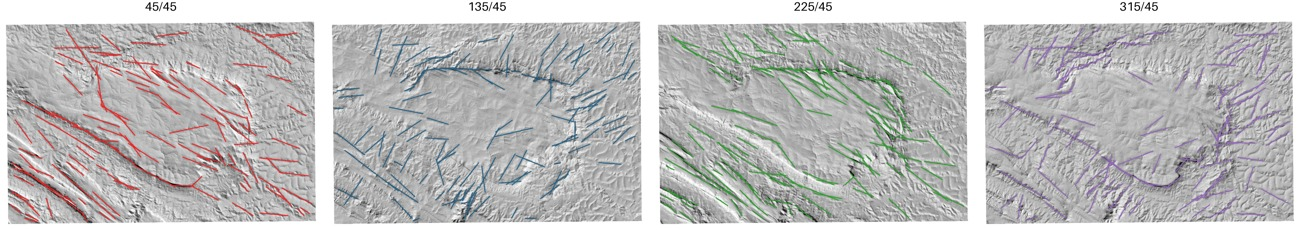

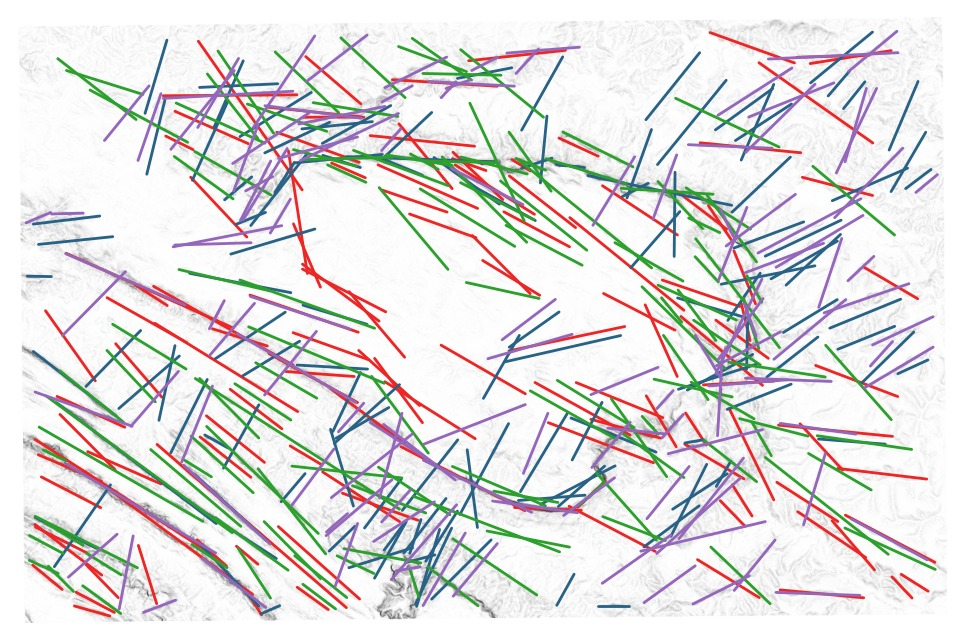

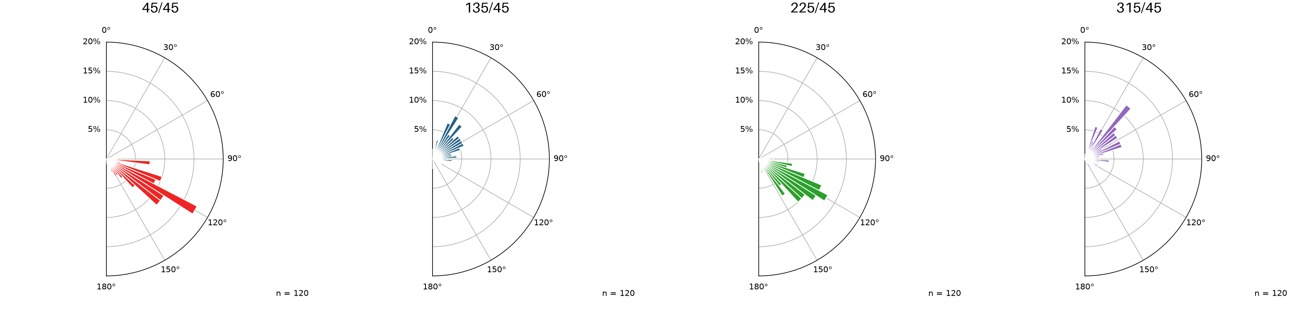

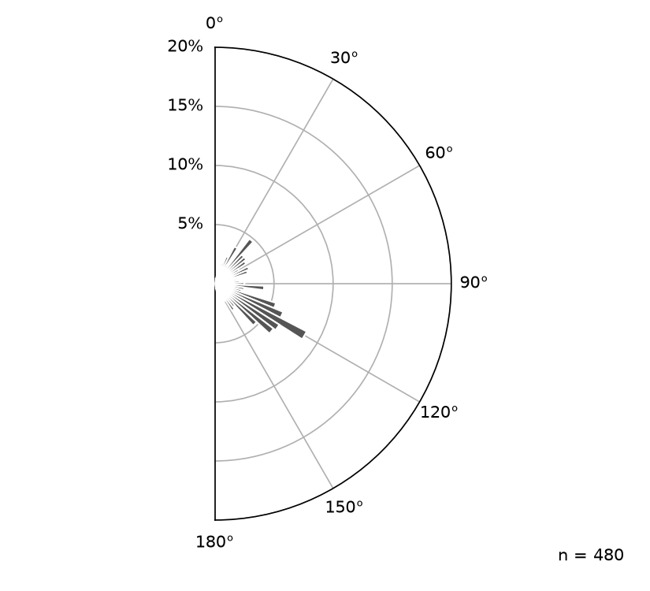

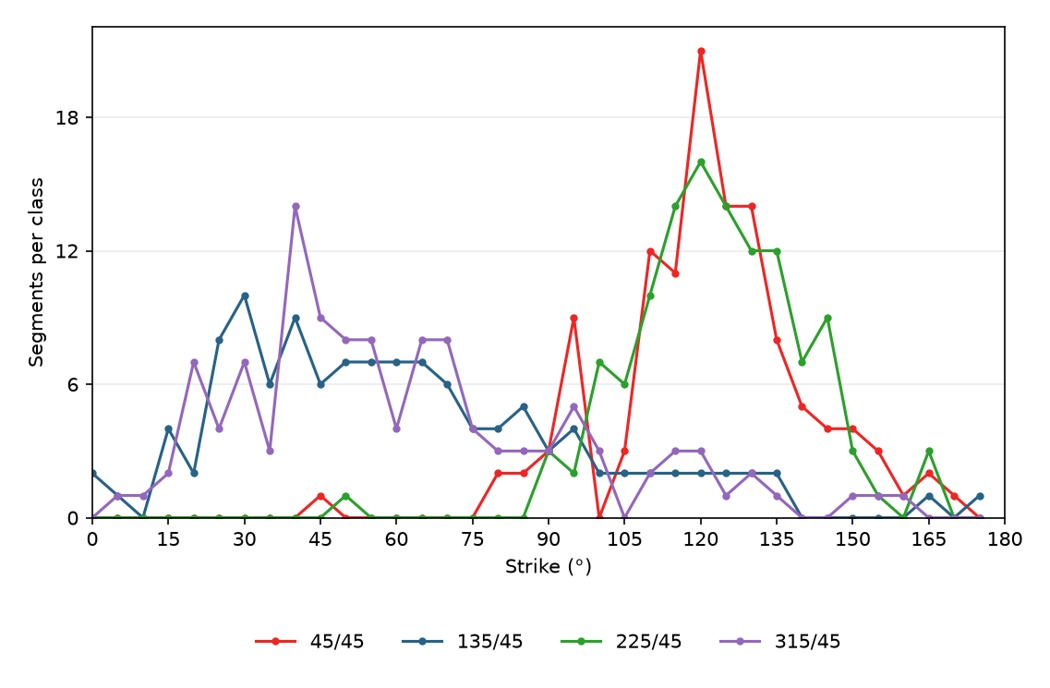

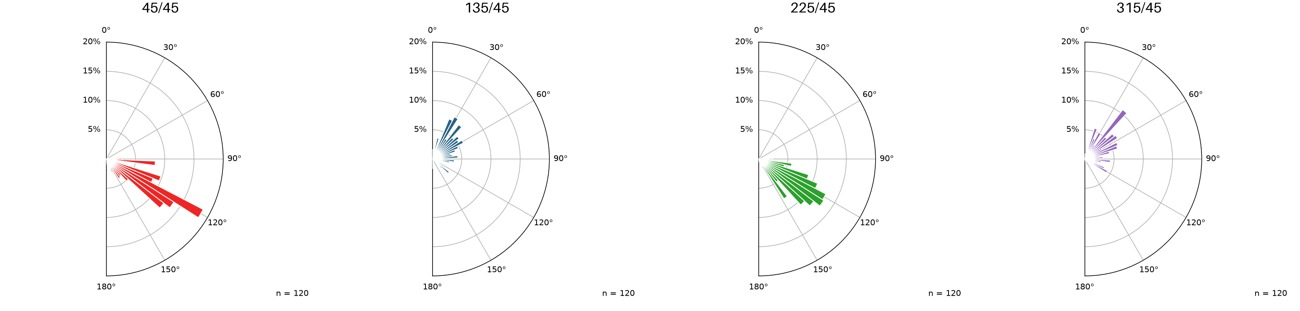

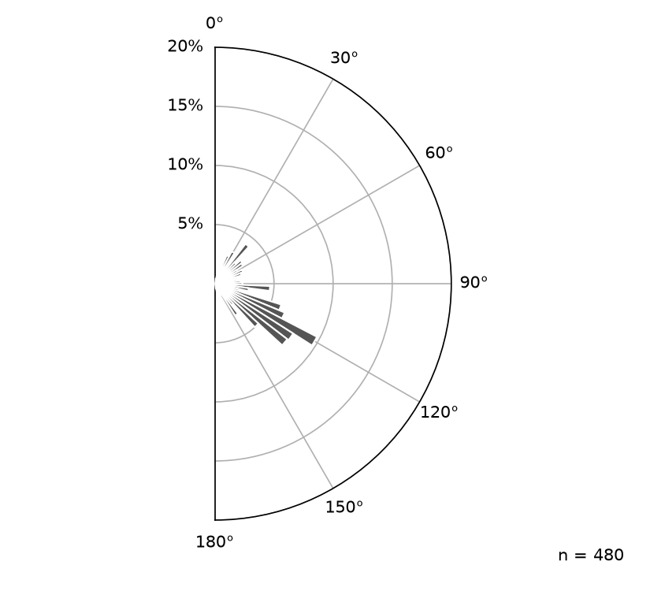

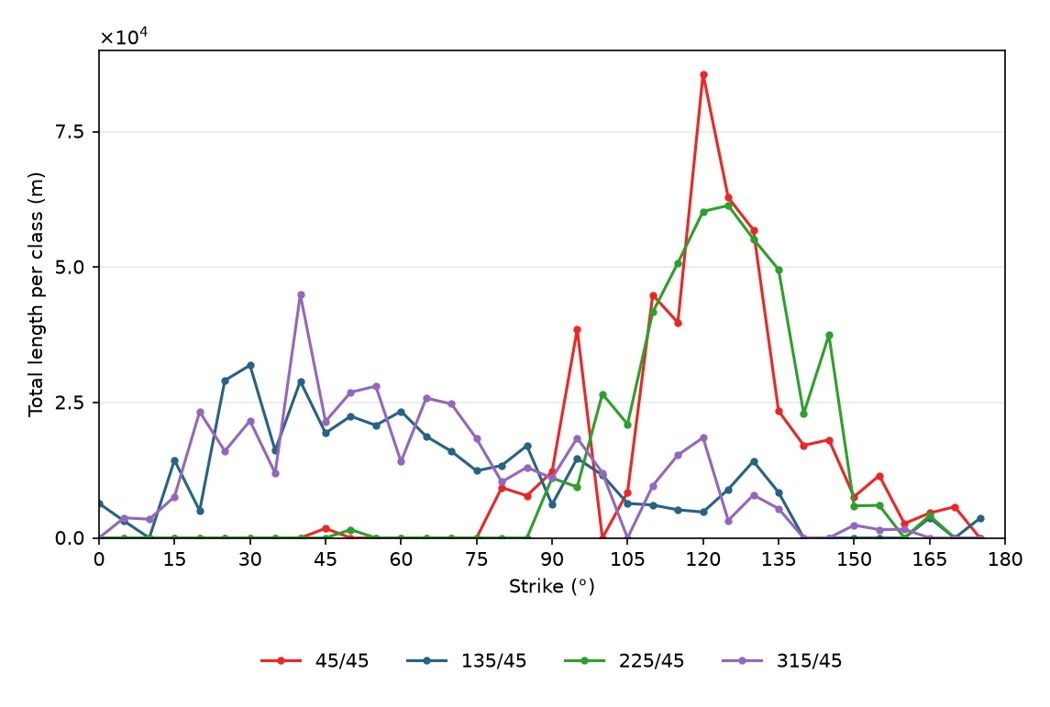

In [13]:
SVG_NAMESPACE = "http://www.w3.org/2000/svg"
XLINK_HREF = "{http://www.w3.org/1999/xlink}href"


def assemble_svg_panel(paths, labels, destination):
    """Arrange Matplotlib SVGs without rasterizing their vector elements."""
    ET.register_namespace("", SVG_NAMESPACE)

    def svg_tag(name):
        return f"{{{SVG_NAMESPACE}}}{name}"

    tiles = [ET.parse(path).getroot() for path in paths]
    sizes = [tuple(map(float, tile.attrib["viewBox"].split()[2:])) for tile in tiles]
    width = max(w for w, _ in sizes)
    height = max(h for _, h in sizes)
    columns = min(4, len(tiles))
    rows = math.ceil(len(tiles) / columns)
    spacing, label_height = 6, 23
    panel_width = width * columns + spacing * (columns - 1)
    panel_height = (height + label_height) * rows + spacing * (rows - 1)
    panel = ET.Element(svg_tag("svg"), {
        "viewBox": f"0 0 {panel_width:g} {panel_height:g}",
        "width": f"{panel_width:g}pt",
        "height": f"{panel_height:g}pt",
    })
    ET.SubElement(panel, svg_tag("rect"), width="100%", height="100%", fill="white")
    for i, (tile, label, (w, h)) in enumerate(zip(tiles, labels, sizes, strict=True)):
        row, column = divmod(i, columns)
        left = column * (width + spacing)
        top = row * (height + label_height + spacing)
        ET.SubElement(panel, svg_tag("text"), {
            "x": str(left + width / 2), "y": str(top + 17), "text-anchor": "middle",
            "font-family": "DejaVu Sans, sans-serif", "font-size": "17",
        }).text = label
        prefix = f"tile{i}-"
        for element in tile.iter():
            if "id" in element.attrib:
                element.attrib["id"] = prefix + element.attrib["id"]
            for key, value in element.attrib.items():
                if key in ("href", XLINK_HREF) and value.startswith("#"):
                    element.attrib[key] = f"#{prefix}{value[1:]}"
                elif "url(#" in value:
                    element.attrib[key] = value.replace("url(#", f"url(#{prefix}")
        tile.set("x", str(left + (width - w) / 2))
        tile.set("y", str(top + label_height + (height - h) / 2))
        tile.set("width", f"{w:g}")
        tile.set("height", f"{h:g}")
        panel.append(tile)
    ET.ElementTree(panel).write(destination, encoding="utf-8", xml_declaration=True)


def assemble_panel(paths, labels, destination):
    """Organize the images in input order with up to four columns."""
    exports_svg = destination.suffix == ".svg"
    if exports_svg:
        assemble_svg_panel(paths, labels, destination)
        paths = [preview_source(path) for path in paths]
    sizes = []
    for path in paths:
        with Image.open(path) as image:
            sizes.append(image.size)

    width = max(size[0] for size in sizes)
    height = max(size[1] for size in sizes)
    columns = min(4, len(paths))
    rows = math.ceil(len(paths) / columns)
    spacing = 12
    label_height = 48
    panel_height = height + label_height
    font = ImageFont.load_default(size=36)
    with Image.new("RGB", (
        width * columns + spacing * (columns - 1),
        panel_height * rows + spacing * (rows - 1),
    ), "white") as panel:
        drawing = ImageDraw.Draw(panel)
        for i, (path, label) in enumerate(zip(paths, labels, strict=True)):
            row, column = divmod(i, columns)
            left = column * (width + spacing)
            top = row * (panel_height + spacing)
            drawing.text((left + width // 2, top + spacing // 2), label,
                         fill="black", font=font, anchor="mt")
            with Image.open(path) as image:
                x = left + (width - image.width) // 2
                y = top + label_height + (height - image.height) // 2
                panel.paste(image.convert("RGB"), (x, y))
        if exports_svg:
            with BytesIO() as preview:
                panel.save(preview, format="PNG")
                _figure_previews[preview_key(destination)] = preview.getvalue()
        else:
            panel.save(destination)


def show_figure(path, width):
    """Embed a raster preview sized for the notebook."""
    with Image.open(preview_source(path)) as image, BytesIO() as preview:
        image.thumbnail((width, image.height))
        image.convert("RGB").save(preview, format="JPEG", quality=92)
        display(NotebookImage(data=preview.getvalue(), format="jpeg"))


def mean_hillshade(paths):
    """Average illumination on the shared UTM grid and keep the nodata mask."""
    total = None
    for path in paths:
        with rasterio.open(path) as raster:
            image = raster.read(1, masked=True).astype(np.float32)
        if total is None:
            total = image
        else:
            total += image
    return total / len(paths)


panel_labels = [labels[light] for light in ILLUMINATIONS]
map_dir = result / "sobreposicoes"
maps = [map_dir / f"{hillshade_path.stem}.{IMAGE_FORMAT}" for hillshade_path in hillshades]
map_panel = map_dir / f"comparacao_iluminacoes.{IMAGE_FORMAT}"
assemble_panel(maps, panel_labels, map_panel)
show_figure(map_panel, 1300)

rasters = [result / "hillshades" / hillshade_path.name for hillshade_path in hillshades]
series = [(segments, colors[light]) for _, light, segments, _ in detections]
map_image = map_dir / f"mapa_combinado.{IMAGE_FORMAT}"
save_overlay(mean_hillshade(rasters), map_image, series)
show_figure(map_image, 1100)

centers, combined_classes = orientation_values(table["strike"], table["comp_m"])
for mode in ROSE_MODES:
    rose_dir = result / "rosetas" / mode
    roses = [rose_dir / f"{hillshade_path.stem}.{IMAGE_FORMAT}" for hillshade_path in hillshades]
    panel = rose_dir / f"comparacao_rosetas.{IMAGE_FORMAT}"
    assemble_panel(roses, panel_labels, panel)
    show_figure(panel, 1300)

    rose = rose_dir / f"roseta_combinada.{IMAGE_FORMAT}"
    save_rose(centers, combined_classes[mode], len(table), rose, "#555555", radial_scales[mode])
    show_figure(rose, 650)

    chart = rose_dir / f"comparacao_cartesiana.{IMAGE_FORMAT}"
    values_by_light = {light: classes[mode] for light, classes in classes_by_light.items()}
    save_cartesian(chart, centers, values_by_light, colors, labels, mode)
    show_figure(chart, 1050)